# 03 · Part II: valuing FN FS9548 as a private-label MBS

Now timely payment is guaranteed by a private financial institution rated **A by S&P Global** instead of the
U.S. government. The rate paths, prepayment model and promised cash flows are exactly those of Part I (same
10,000 paths). The only change is that promised cash flows are replaced by **expected** cash flows using the
guarantor's probability of default, probability of survival and recovery rate (expected cash-flow approach,
Topic 5).

In [1]:
import sys
import json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

import mbs_model as m
import plot_style as ps

ps.apply()
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

case = m.build_base_case()
inputs, paths = case["inputs"], case["paths"]
T, B0 = inputs["wam_months"], inputs["current_balance"]
lag = inputs["payment_lag_months_after_month_start"]
mkt = m.market_prices(inputs)
AI = m.accrued_interest(inputs)
base = m.BASE

## Credit inputs

| Input | Value | Justification |
|---|---|---|
| Annual probability of default | **0.10%** | S&P's long-run 'A' default studies show roughly 0.05% one-year and about 0.4–0.5% five-year cumulative default rates. That is about 0.1% per year on average over a 4–5 year horizon, which matches this pool's 52-month life. |
| Recovery rate | **40%** | Standard senior unsecured recovery assumption for a financial institution. |
| Hazard | constant | Monthly survival $S_t = (1-\text{PD})^{t/12}$ |

These are real-world (historical) default rates. A market-implied (risk-neutral) PD backed out from the
guarantor's credit spread would be several times larger, so a wide range of PDs is shown in the sensitivity
table below.

In [2]:
pd_a, R = base["pd_annual"], base["recovery"]
S = m.survival_curve(pd_a, T)
credit = pd.DataFrame({"month": np.arange(1, T + 1), "survival S_t": S[1:],
                       "marginal default S_{t-1}-S_t": S[:-1] - S[1:]})
print(f"monthly PD = 1-(1-{pd_a})^(1/12) = {1-(1-pd_a)**(1/12):.6%};  "
      f"cumulative PD over 52 months = {1-S[-1]:.4%}")
credit.iloc[[0, 1, 2, 11, 23, 35, 51]]

monthly PD = 1-(1-0.001)^(1/12) = 0.008337%;  cumulative PD over 52 months = 0.4326%


,month,survival S_t,marginal default S_{t-1}-S_t
0,1,0.999917,0.000083
1,2,0.999833,0.000083
2,3,0.999750,0.000083
11,12,0.999000,0.000083
23,24,0.998001,0.000083
35,36,0.997003,0.000083
51,52,0.995674,0.000083


## Expected cash flows

If the guarantor survives through month $t$ the investor receives the promised cash flow $\text{CF}_t$. If it
defaults during month $t$ the investor recovers $R$ times the outstanding principal claim $B_{t-1}$ and
receives nothing after that:

$$E[\text{CF}_t] = S_t\,\text{CF}_t + (S_{t-1} - S_t)\,R\,B_{t-1}.$$

*Correction vs. the original model:* the original used $\text{CF}_t\,(S_t + R\,q_t)$, i.e. recovery only on
that month's cash flow. When a guarantor defaults, the claim is the outstanding principal, not one month's
payment. The original formula therefore never paid the recovery on the remaining balance.

Each path's expected cash flows are discounted with the same path discount factors as in Part I.

In [3]:
summary, prices, ecf, _ = m.value_private_label(case)
agency, agency_prices, cf = m.value_agency(case)

first = pd.DataFrame({
    "month": np.arange(1, T + 1),
    "promised CF (path 1)": cf.cash_flow[0],
    "begin balance": cf.begin_balance[0],
    "S_t": S[1:],
    "S_{t-1}-S_t": S[:-1] - S[1:],
    "expected CF (path 1)": ecf[0],
})
first["credit haircut"] = first["promised CF (path 1)"] - first["expected CF (path 1)"]
first.iloc[[0, 1, 2, 23, 50, 51]]

,month,promised CF (path 1),begin balance,S_t,S_{t-1}-S_t,expected CF (path 1),credit haircut
0,1,"88,275.650948","2,986,518.000000",0.999917,0.000083,"88,367.887526",-92.236578
1,2,"88,100.392041","2,905,708.644052",0.999833,0.000083,"88,182.595818",-82.203777
2,3,"86,412.993094","2,824,872.523621",0.999750,0.000083,"86,485.571635",-72.578541
23,24,"62,619.567512","1,372,157.087099",0.998001,0.000083,"62,540.062877",79.504635
50,51,"39,215.028971","77,614.429681",0.995757,0.000083,"39,051.213290",163.815681
51,52,"38,689.920376","38,593.436784",0.995674,0.000083,"38,523.824842",166.095535


In [4]:
oas_pl = m.solve_oas(ecf, paths.rates, B0, mkt["bid"] + AI, lag)
spread_equiv = brentq(lambda s: m.value_agency(case, spread=s)[0]["clean_price"] - summary["clean_price"],
                      -0.01, 0.05)
breakeven_pd = brentq(lambda p: m.value_private_label(case, pd_annual=p)[0]["clean_price"] - mkt["bid"],
                      1e-6, 0.2)
part2 = {
    "pd_annual": pd_a,
    "recovery": R,
    "monthly_pd": 1 - (1 - pd_a) ** (1 / 12),
    "cumulative_pd_52m": 1 - S[-1],
    "private_full_price": summary["full_price"],
    "private_clean_price": summary["clean_price"],
    "std_error": summary["std_error"],
    "agency_clean_price": agency["clean_price"],
    "credit_discount_points": agency["clean_price"] - summary["clean_price"],
    "credit_spread_equiv_bp": spread_equiv * 1e4,
    "private_minus_bid": summary["clean_price"] - mkt["bid"],
    "oas_bp_at_bid": oas_pl * 1e4,
    "breakeven_pd_annual": breakeven_pd,
}
pd.Series(part2).to_frame("Part II result")

,Part II result
pd_annual,0.001000
recovery,0.400000
monthly_pd,0.000083
cumulative_pd_52m,0.004326
private_full_price,98.331520
private_clean_price,98.089854
std_error,0.000266
agency_clean_price,98.197988
credit_discount_points,0.108135
credit_spread_equiv_bp,6.022075


## Sensitivity to the credit assumptions
Same paths and cash flows; only PD and recovery change.

In [5]:
pds = [0.0005, 0.0010, 0.0025, 0.0050, 0.0100, 0.0200]
recs = [0.25, 0.40, 0.60]
grid = pd.DataFrame(index=[f"{p:.2%}" for p in pds], columns=[f"R = {r:.0%}" for r in recs], dtype=float)
for p in pds:
    for r in recs:
        grid.loc[f"{p:.2%}", f"R = {r:.0%}"] = m.value_private_label(case, pd_annual=p, recovery=r)[0]["clean_price"]
grid.index.name = "annual PD"
grid.style.format("{:.3f}")

,R = 25%,R = 40%,R = 60%
annual PD,,,
0.05%,98.130,98.144,98.162
0.10%,98.062,98.090,98.127
0.25%,97.859,97.928,98.020
0.50%,97.522,97.659,97.842
1.00%,96.851,97.125,97.489
2.00%,95.527,96.069,96.791


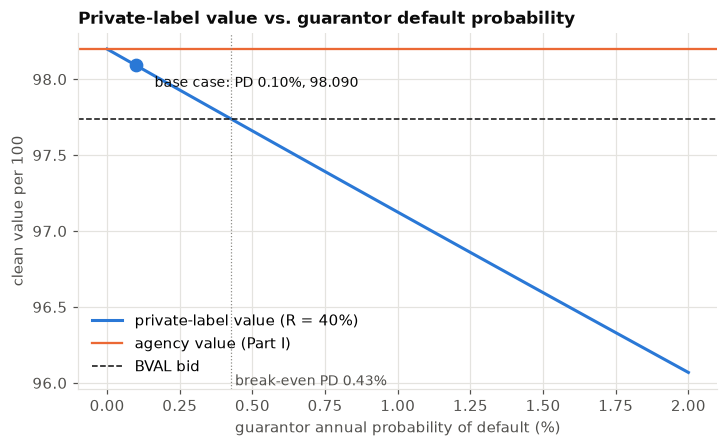

In [6]:
pd_line = np.linspace(0.0, 0.02, 41)
vals = [m.value_private_label(case, pd_annual=p)[0]["clean_price"] for p in pd_line]
fig, ax = plt.subplots()
ax.plot(pd_line * 100, vals, color=ps.BLUE, label="private-label value (R = 40%)")
ax.axhline(agency["clean_price"], color=ps.ORANGE, lw=1.5, ls="-", label="agency value (Part I)")
ax.axhline(mkt["bid"], color=ps.INK, lw=1, ls="--", label="BVAL bid")
ax.plot([pd_a * 100], [summary["clean_price"]], "o", color=ps.BLUE, ms=8)
ax.annotate(f"base case: PD 0.10%, {summary['clean_price']:.3f}", (pd_a * 100, summary["clean_price"]),
            xytext=(12, -14), textcoords="offset points", fontsize=9, color=ps.INK)
ax.axvline(breakeven_pd * 100, color=ps.REF, lw=0.8, ls=":")
ax.text(breakeven_pd * 100, ax.get_ylim()[0], f" break-even PD {breakeven_pd:.2%}", fontsize=9,
        color=ps.INK_2, va="bottom")
ax.set_xlabel("guarantor annual probability of default (%)")
ax.set_ylabel("clean value per 100")
ax.set_title("Private-label value vs. guarantor default probability")
ax.legend(loc="lower left")
ps.save(fig, "07_private_label_pd_sensitivity")

In [7]:
results_path = m.OUTPUT_DIR / "results.json"
results = json.loads(results_path.read_text()) if results_path.exists() else {}
results["part2"] = part2 | {"credit_grid": {k: v.to_dict() for k, v in grid.T.iterrows()}}
results_path.write_text(json.dumps(results, indent=2, default=float))
np.savetxt(m.OUTPUT_DIR / "private_label_path_prices_full.csv", prices, fmt="%.8f",
           header="full price per 100", comments="")
print("saved", results_path.name)

saved results.json


## Conclusion, Part II
With an A-rated private guarantor (PD 0.10% a year, 40% recovery) the expected cash flows are only slightly
lower than the promised ones. Over the pool's short remaining life the cumulative default probability is under
0.5%, and 40% of the outstanding claim is recovered on default. The credit adjustment costs about **0.1 point**,
equivalent to a few basis points of spread. The private-label value is still above the agency's BVAL bid.

**Comment.** The conclusion depends heavily on which default probability is used. Historical A-rated default
rates give a small adjustment. A guarantor PD of about 0.4% a year or more (the break-even PD shown above) is
enough to push the value below today's agency price. Market-implied PDs for A-rated financials are typically
in that range or higher, because credit spreads also price risk premia and liquidity. Under those assumptions a
private-label version would have to trade at a discount to the agency pool. The expected cash-flow approach also
ignores **wrong-way risk**: a guarantor is most likely to fail in a housing downturn, which is exactly when it
is needed. That is a further reason to treat the base-case adjustment as a lower bound.